# Sargassum Seasonal Heatmap — from saved SGI zarr cubes
Loads coverage footprints from a saved pickle (no S3 calls unless the pickle doesn't exist yet), thresholds a chosen year's monthly SGI cubes, sums a month range, and plots one heatmap.

### 1. Imports

In [1]:
import os
import re
import glob
import calendar
import pickle
from pathlib import Path

import numpy as np
import xarray as xr
import s3fs

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import warnings
warnings.filterwarnings('ignore')

### 2. Grid definition

In [2]:
lon_1d = np.arange(-70, -20, 0.05)
lat_1d = np.arange(-5,   20, 0.05)
target_lons, target_lats = np.meshgrid(lon_1d, lat_1d)

### 3. Find the saved monthly SGI datacubes on disk

In [3]:
zarr_root = '/home/nandii/olci_sg/mo_zarrs'

cube_paths = {}
for path in sorted(glob.glob(os.path.join(zarr_root, 'SGI_*.zarr'))):
    match = re.search(r'SGI_(\d{4})(\d{2})\.zarr', os.path.basename(path))
    year, month = int(match.group(1)), int(match.group(2))
    cube_paths[(year, month)] = path

print(f"{len(cube_paths)} cube(s) found")

44 cube(s) found


### 4. Load 2018 coverage footprints from the saved pickle

Loads straight from disk — no S3, no `composites`, no `footprint_cache`. If the pickle doesn't exist yet, this builds it once (needs S3 + the 2018 cubes) and saves it, so this fallback only ever runs a single time, ever.

In [4]:
footprints_path = Path('/home/nandii/olci_sg/footprint.pkl')

if footprints_path.exists():
    with open(footprints_path, 'rb') as f:
        footprints_2018 = pickle.load(f)
    print(f"Loaded {len(footprints_2018)} footprints from {footprints_path}")
else:
    print("footprint.pkl not found — building it once from 2018 cubes (S3 required)")

    fs = s3fs.S3FileSystem(
        client_kwargs = {
            'endpoint_url' : 'https://s3.waw3-1.cloudferro.com',
            'region_name'  : 'waw3-1'
        },
        config_kwargs = {'signature_version': 's3v4'},
        profile = 'laurenb'
    )
    S3_BUCKET = 'olci_l1_fr'

    def get_scene_footprint(scene_name, fs, bucket = S3_BUCKET, step = 20):
        prefix = f'{bucket}/{scene_name}'
        with fs.open(f'{prefix}/geo_coordinates.nc', cache_type = 'blockcache') as f:
            geo = xr.open_dataset(f)
            lat = geo['latitude'].values.copy()
            lon = geo['longitude'].values.copy()
        top    = np.s_[0, ::step]
        right  = np.s_[::step, -1]
        bottom = np.s_[-1, ::-step]
        left   = np.s_[::-step, 0]
        lat_perimeter = np.concatenate([lat[top], lat[right], lat[bottom], lat[left]])
        lon_perimeter = np.concatenate([lon[top], lon[right], lon[bottom], lon[left]])
        return lat_perimeter, lon_perimeter

    cube_paths_2018 = {k: v for k, v in cube_paths.items() if k[0] == 2018}
    assert len(cube_paths_2018) > 0, "No 2018 cubes found — can't build footprints without them."

    footprints_2018 = []
    for (year, month), zarr_path in sorted(cube_paths_2018.items()):
        ds_cube = xr.open_zarr(zarr_path)
        for name in ds_cube['scene_name'].values:
            footprints_2018.append(get_scene_footprint(name, fs, bucket = S3_BUCKET))

    with open(footprints_path, 'wb') as f:
        pickle.dump(footprints_2018, f)
    print(f"Saved {len(footprints_2018)} footprints to {footprints_path} — this fallback should never run again")


Loaded 552 footprints from /home/nandii/olci_sg/footprint.pkl


### 5. Threshold a chosen year's SGI cubes into monthly detection counts

In [5]:
threshold   = -2
bloom_year  = 2026

bloom = {}
cube_paths_year = {k: v for k, v in cube_paths.items() if k[0] == bloom_year}
assert len(cube_paths_year) > 0, f"No cubes found for {bloom_year} in cube_paths."

for (year, month), zarr_path in sorted(cube_paths_year.items()):
    ds_cube = xr.open_zarr(zarr_path)
    sgssm_mask = ds_cube['SGI'] >= threshold
    valid_mask = np.isfinite(ds_cube['SGI'])
    detection_count = sgssm_mask.sum(dim = 'scene')
    valid_count     = valid_mask.sum(dim = 'scene')
    bloom[(year, month)] = {
        'detection_count' : detection_count.values,
        'coverage'        : valid_count.values}

print(f"Built {len(bloom)} months: {sorted(bloom.keys())}")

Built 4 months: [(2026, 5), (2026, 6), (2026, 7), (2026, 8)]


In [6]:
total_count = np.sum([v['detection_count'] for v in bloom.values()], axis = 0)

### 7. Plot the seasonal heatmap

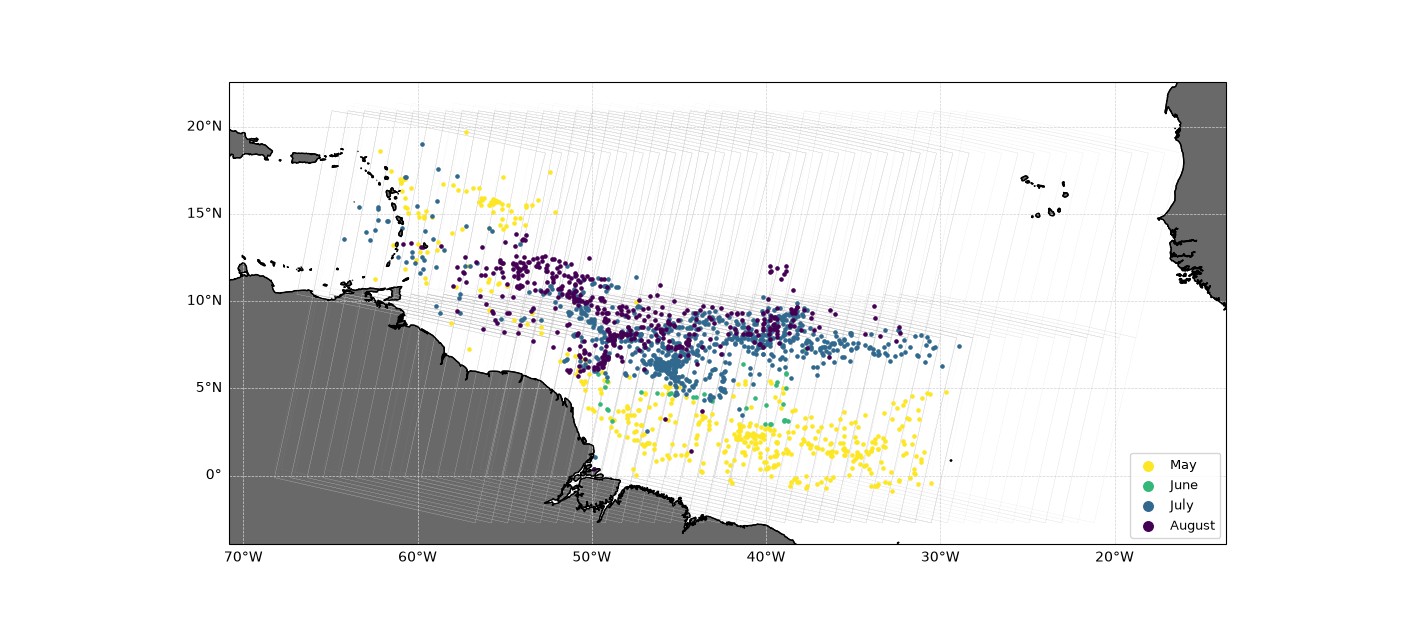

In [7]:
def plot_seasonal_heatmap_by_month(selected, footprints, target_lons, target_lats, title):
    fig, ax = plt.subplots(figsize = (14, 6), subplot_kw = {'projection': ccrs.PlateCarree()})
    ax.set_facecolor('white')
    ax.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '10m',
                                                 edgecolor = 'black', facecolor = 'dimgrey'), zorder = 1)

    months = sorted(month for _, month in selected)
    norm = plt.Normalize(vmin = min(months), vmax = max(months))
    cmap = plt.get_cmap('viridis_r')

    for (year, month), data in sorted(selected.items()):
        rows, cols = np.where(data['detection_count'] > 0)
        ax.scatter(target_lons[rows, cols], target_lats[rows, cols],
                   color = cmap(norm(month)), s = 21, marker = '.',
                   label = calendar.month_name[month], transform = ccrs.PlateCarree(), zorder = 4)

    gl = ax.gridlines(draw_labels = True, color = 'lightgrey', linewidth = 0.5,
                       linestyle = '--', zorder = 3)
    gl.top_labels   = False
    gl.right_labels = False

    for lat_perimeter, lon_perimeter in footprints:
        ax.plot(lon_perimeter, lat_perimeter, color = 'silver', linestyle = '-.',
                linewidth = 0.05, transform = ccrs.PlateCarree(), zorder = 2)

    ax.coastlines(resolution = '10m', linewidth = 0.8, zorder = 100)
    ax.set_title(title, fontsize = 13, weight = 'bold')
    ax.legend(loc = 'lower right', markerscale = 3, fontsize = 9, frameon = True)
    plt.show()
    return fig


fig = plot_seasonal_heatmap_by_month(bloom, footprints_2018, target_lons, target_lats,
                                     title = f"Sargassum Detection Count by Month — {bloom_year} (coverage shown)")

### 8. Save the figure

In [8]:
fig.savefig(f'Sargassum{bloom_year}.png', dpi = 300, bbox_inches = 'tight')

In [9]:
year_counts = {}

for (year, month), zarr_path in sorted(cube_paths.items()):
    ds_cube = xr.open_zarr(zarr_path)
    sgssm_mask = ds_cube['SGI'] >= threshold
    year_counts[year] = year_counts.get(year, 0) + int(sgssm_mask.sum())

for year, count in sorted(year_counts.items()):
    print(year, count)

2016 97
2017 272
2018 1263
2019 775
2020 1082
2021 1572
2022 2582
2023 1263
2024 1166
2025 3830
2026 1825
